# SVIX Regression Against Synthetic SVXY −1x

#### **MScFE 690 Capstone -Group 17843**

**Authors**: Edgar NAVA-edgar.nava@grovewm.com & Celestin NYANDWI-celestinnyandwi48@gmail.com

Notebook **12** supports Section **4.8.1** of the **Extended Capstone Research Report**. We compare observed SVIX with synthetic SVXY −1x through a regression of daily simple Close returns. This is an empirical comparison of the two series, not a trading-system backtest or proof that the instruments are interchangeable.


## 1. Settings and data sources

Use the frozen local CSV snapshots in `data/`. SVIX is the existing Yahoo Finance history used by the SVIX application notebook; synthetic SVXY −1x is the project's processed series from Notebook 02. No download is performed. The source files end on 16 September 2026.

The dependent variable is SVIX daily return; the explanatory variable is synthetic SVXY −1x daily return. Use Close consistently with the project. These are price returns, not independently verified total returns. A separate check below compares SVIX Close and Adj Close and reports corporate actions.

Requirements: Python, numpy, pandas, matplotlib, statsmodels, and Jupyter. Run all cells in order. Tables are displayed below, and the figure is saved to `Results/` beside the notebook. To update the study, replace the input snapshots deliberately and rerun.

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels
import statsmodels.api as sm
from IPython.display import display, Markdown

DATA_DIR = Path.cwd() / "data"
OUTPUT_DIR = Path.cwd() / "Results"
OUTPUT_DIR.mkdir(exist_ok=True)
START = "2022-03-30"
END = "2026-09-16"
PRETEST_END = "2023-12-29"
TEST_START = "2024-01-01"
HAC_LAGS = 5
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "figure.facecolor": "white"})
inputs = {"SVIX": DATA_DIR / "SVIX_data.csv",
          "SVXY_ONEx": DATA_DIR / "SVXY_synth-ONEx.csv"}
manifest = {k: {"file": str(p), "sha256": hashlib.sha256(p.read_bytes()).hexdigest()}
            for k, p in inputs.items()}


Matplotlib is building the font cache; this may take a moment.


## 2. Validate and align the observations

Reject duplicate dates, missing or nonpositive Close prices, nonfinite values, and dates present in only one instrument within the overlap. Compute returns only after matching the price dates, so both returns cover identical intervals. The first shared price observation establishes the base and has no regression return. No forward filling, interpolation, or outlier removal is used.

In [2]:
def load_prices(path):
    frame = pd.read_csv(path)
    frame["Date"] = pd.to_datetime(frame["Date"], errors="raise")
    if frame["Date"].isna().any() or frame["Date"].duplicated().any():
        raise ValueError(f"Invalid or duplicate dates: {path}")
    frame = frame.set_index("Date").sort_index()
    frame["Close"] = pd.to_numeric(frame["Close"], errors="raise")
    if not np.isfinite(frame["Close"]).all() or (frame["Close"] <= 0).any():
        raise ValueError(f"Invalid Close prices: {path}")
    return frame

raw = {k: load_prices(p) for k, p in inputs.items()}
coverage = pd.DataFrame({k: {"First price": f.index.min(), "Last price": f.index.max(),
                             "Price observations": len(f)} for k, f in raw.items()}).T
svix = raw["SVIX"]
if "Adj Close" in svix:
    print("Maximum absolute SVIX Close–Adj Close difference:",
          (svix["Close"] - pd.to_numeric(svix["Adj Close"])).abs().max())
action_cols = [k for k in ["Dividends", "Stock Splits", "Capital Gains"] if k in svix]
if action_cols:
    actions = svix[action_cols].apply(pd.to_numeric)
    display(actions.loc[actions.ne(0).any(axis=1)])
lo = max(pd.Timestamp(START), *(f.index.min() for f in raw.values()))
hi = min(pd.Timestamp(END), *(f.index.max() for f in raw.values()))
series = {k: f.loc[lo:hi, "Close"] for k, f in raw.items()}
unmatched = series["SVIX"].index.symmetric_difference(series["SVXY_ONEx"].index)
if len(unmatched):
    raise ValueError(f"Unmatched dates in overlap; inspect before calculating returns: {unmatched.tolist()}")
prices = pd.concat(series, axis=1).dropna()
if len(prices) < 30:
    raise ValueError("Insufficient common price history")
returns = prices.pct_change(fill_method=None).iloc[1:]
assert np.isfinite(returns.to_numpy()).all()
display(coverage)
print(f"Common prices: {prices.index.min().date()} to {prices.index.max().date()} ({len(prices):,})")
print(f"Regression returns: {returns.index.min().date()} to {returns.index.max().date()} ({len(returns):,})")
display(returns.head())


Maximum absolute SVIX Close–Adj Close difference: 0.0


,Dividends,Stock Splits,Capital Gains
Date,,,


,First price,Last price,Price observations
SVIX,2022-03-30 00:00:00,2026-09-16 00:00:00,1120
SVXY_ONEx,2011-10-04 00:00:00,2026-09-16 00:00:00,3759


Common prices: 2022-03-30 to 2026-09-16 (1,120)
Regression returns: 2022-03-31 to 2026-09-16 (1,119)


,SVIX,SVXY_ONEx
Date,,
2022-03-31,-0.050710,-0.052124
2022-04-01,0.040598,0.039956
2022-04-04,0.049281,0.051033
2022-04-05,-0.086106,-0.084808
2022-04-06,-0.021413,-0.021958


## 3. OLS regression and comparison across periods

Estimate with an intercept:

$$r^{SVIX}_t = \alpha + \beta r^{SVXY,-1x}_t + \varepsilon_t,\qquad r_t=P_t/P_{t-1}-1.$$

Returns enter in decimal units. Alpha is a **daily** intercept; beta measures contemporaneous sensitivity. A beta near one and alpha near zero are useful comparison points, but high R² alone does not establish equivalence. Report ordinary least-squares point estimates with Newey–West HAC standard errors (5 lags) and 95% confidence intervals.

The full-overlap and period-specific fits are descriptive and in sample. A separate frozen fit through 29 December 2023 is evaluated from 2024 onward without refitting. This is a temporal robustness check for this comparison, not a claim of a previously untouched trading holdout. No pre-inception SVIX observations are constructed.

In [3]:
def fit_model(frame):
    if len(frame) < 20 or frame["SVXY_ONEx"].std() == 0:
        raise ValueError("Insufficient observations or zero explanatory variance")
    X = sm.add_constant(frame[["SVXY_ONEx"]], has_constant="add")
    return sm.OLS(frame["SVIX"], X).fit(cov_type="HAC", cov_kwds={"maxlags": HAC_LAGS})

samples = {"Full overlap": returns,
           "Pre-Test overlap": returns.loc[:PRETEST_END],
           "Test overlap": returns.loc[TEST_START:]}
models = {name: fit_model(frame) for name, frame in samples.items()}
rows = []
for name, frame in samples.items():
    fit = models[name]
    ci = fit.conf_int()
    rows.append({"Sample": name, "First return": str(frame.index.min().date()),
                 "Last return": str(frame.index.max().date()), "N": len(frame),
                 "Alpha daily (pp)": fit.params["const"] * 100,
                 "Alpha 95% low (pp)": ci.loc["const", 0] * 100,
                 "Alpha 95% high (pp)": ci.loc["const", 1] * 100,
                 "Beta": fit.params["SVXY_ONEx"],
                 "Beta 95% low": ci.loc["SVXY_ONEx", 0],
                 "Beta 95% high": ci.loc["SVXY_ONEx", 1],
                 "R squared": fit.rsquared,
                 "Correlation": frame.corr().loc["SVIX", "SVXY_ONEx"],
                 "RMSE (pp)": np.sqrt(np.mean(fit.resid ** 2)) * 100})
summary = pd.DataFrame(rows).set_index("Sample")
display(summary.round(6))
print(models["Full overlap"].summary())

frozen = models["Pre-Test overlap"]
test = samples["Test overlap"]
pred = frozen.predict(sm.add_constant(test[["SVXY_ONEx"]], has_constant="add"))
errors = test["SVIX"] - pred
holdout = pd.Series({"N": len(test), "RMSE (pp)": np.sqrt(np.mean(errors**2))*100,
                     "MAE (pp)": np.mean(abs(errors))*100,
                     "Mean error (pp)": errors.mean()*100,
                     "Predictive R squared": 1 - np.sum(errors**2) / np.sum((test["SVIX"]-test["SVIX"].mean())**2)})
display(holdout.to_frame("Frozen pre-Test fit evaluated on Test"))


,First return,Last return,N,Alpha daily (pp),Alpha 95% low (pp),Alpha 95% high (pp),Beta,Beta 95% low,Beta 95% high,R squared,Correlation,RMSE (pp)
Sample,,,,,,,,,,,,
Full overlap,2022-03-31,2026-09-16,1119,-0.036436,-0.052473,-0.020399,0.953318,0.934027,0.972609,0.986586,0.993271,0.474628
Pre-Test overlap,2022-03-31,2023-12-29,440,-0.023803,-0.043396,-0.004209,0.971452,0.956460,0.986444,0.986834,0.993395,0.417891
Test overlap,2024-01-02,2026-09-16,679,-0.047452,-0.070784,-0.024120,0.945456,0.920426,0.970486,0.986703,0.993329,0.503460


                            OLS Regression Results                            
Dep. Variable:                   SVIX   R-squared:                       0.987
Model:                            OLS   Adj. R-squared:                  0.987
Method:                 Least Squares   F-statistic:                     9381.
Date:                Mon, 02 Nov 2026   Prob (F-statistic):               0.00
Time:                        13:12:17   Log-Likelihood:                 4399.3
No. Observations:                1119   AIC:                            -8795.
Df Residuals:                    1117   BIC:                            -8785.
Df Model:                           1                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0004   8.18e-05     -4.453      0.0

,Frozen pre-Test fit evaluated on Test
N,679.000000
RMSE (pp),0.518066
MAE (pp),0.294169
Mean error (pp),-0.026493
Predictive R squared,0.985920


## 4. Graphs and residual diagnostics

The scatter plot compares daily returns with the fitted OLS line and the identity line. Rebased prices start at 100 on the first common date and show compounded price performance. Residuals and the largest daily differences help identify departures that a single R² can conceal. No observation is excluded because of a large difference.

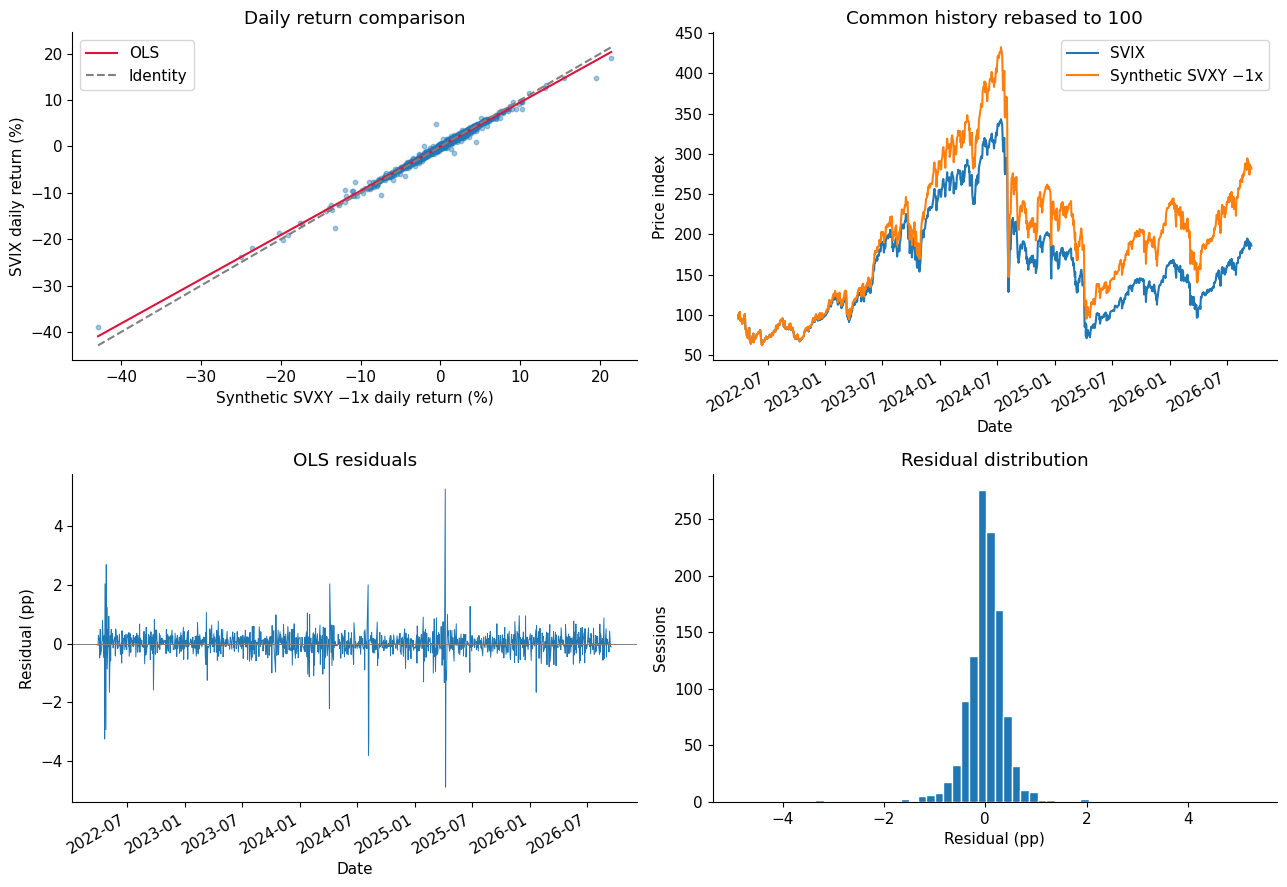

,SVIX,SVXY_ONEx,OLS fitted SVIX,OLS residual,SVIX minus SVXY,Frozen prediction
Date (values in pp),,,,,,
2025-04-07,4.7506,-0.4911,-0.5046,5.2552,5.2417,-0.5009
2024-08-06,14.7368,19.4799,18.5341,-3.7972,-4.7430,18.8999
2025-04-08,-17.5359,-13.2385,-12.6570,-4.8789,-4.2974,-12.8844
2024-08-05,-38.9068,-42.8686,-40.9038,1.9971,3.9618,-41.6686
2024-08-07,0.9174,4.5074,4.2606,-3.3431,-3.5900,4.3549
2022-04-26,-7.5960,-10.7448,-10.2796,2.6836,3.1488,NaN
2022-04-25,-1.3180,1.7215,1.6047,-2.9226,-3.0394,NaN
2022-04-21,-10.3679,-7.4376,-7.1268,-3.2411,-2.9303,NaN
2022-04-22,-9.4030,-11.9551,-11.4335,2.0305,2.5521,NaN


In [4]:
fit = models["Full overlap"]
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
x, y = returns["SVXY_ONEx"]*100, returns["SVIX"]*100
axes[0, 0].scatter(x, y, s=10, alpha=.4)
grid = np.linspace(x.min(), x.max(), 200)
axes[0, 0].plot(grid, fit.params["const"]*100 + fit.params["SVXY_ONEx"]*grid, color="crimson", label="OLS")
axes[0, 0].plot(grid, grid, "--", color="gray", label="Identity")
axes[0, 0].set(xlabel="Synthetic SVXY −1x daily return (%)", ylabel="SVIX daily return (%)", title="Daily return comparison")
axes[0, 0].legend()
(prices / prices.iloc[0] * 100).rename(columns={"SVXY_ONEx": "Synthetic SVXY −1x"}).plot(ax=axes[0, 1])
axes[0, 1].set(title="Common history rebased to 100", ylabel="Price index")
(fit.resid*100).plot(ax=axes[1, 0], linewidth=.7)
axes[1, 0].axhline(0, color="gray", linewidth=.7)
axes[1, 0].set(title="OLS residuals", ylabel="Residual (pp)")
axes[1, 1].hist(fit.resid*100, bins=60, edgecolor="white")
axes[1, 1].set(title="Residual distribution", xlabel="Residual (pp)", ylabel="Sessions")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "SVIX_SVXY_ONEx_regression.png", dpi=180, bbox_inches="tight")
plt.show()
comparison = returns.copy()
comparison["OLS fitted SVIX"] = fit.fittedvalues
comparison["OLS residual"] = fit.resid
comparison["SVIX minus SVXY"] = returns["SVIX"] - returns["SVXY_ONEx"]
comparison["Frozen prediction"] = np.nan
comparison.loc[test.index, "Frozen prediction"] = pred
largest = comparison.reindex(comparison["SVIX minus SVXY"].abs().sort_values(ascending=False).head(10).index)
display((largest * 100).round(4).rename_axis("Date (values in pp)"))
